## 1. Import library dan konfigurasi

In [10]:
from pathlib import Path
import json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
import seaborn as sns

DATASET_DIR = Path("processed_data")
OUTPUT_DIR = Path("outputs")
IMG_SIZE = 48
BATCH_SIZE = 32
EPOCHS = 30
LEARNING_RATE = 0.001
SEED = 42
TEST_SIZE = 0.20
VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
CLASS_NAMES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
EMOTION_MAP = {"angry":"angry","anger":"angry","disgust":"disgust","fear":"fear",
               "happy":"happy","happiness":"happy","neutral":"neutral",
               "sad":"sad","sadness":"sad","surprise":"surprise","surprised":"surprise"}
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
OUTPUT_DIR.mkdir(exist_ok=True, parents=True)
print("TensorFlow:", tf.__version__)

TensorFlow: 2.21.0


## 2. Membaca dataset dan memahami struktur folder

In [11]:
def normalize_label(folder_name):
    key = folder_name.strip().lower().replace(" ", "_").replace("-", "_")
    return EMOTION_MAP.get(key)

def collect_images(root):
    if not root.exists():
        raise FileNotFoundError(f"Folder {root.resolve()} tidak ditemukan.")
    records = []
    split_dirs = [p for p in root.iterdir() if p.is_dir() and p.name.lower() in
                  {"train","training","test","testing","val","valid","validation"}]
    if split_dirs:
        for split_dir in split_dirs:
            for class_dir in split_dir.iterdir():
                if class_dir.is_dir() and normalize_label(class_dir.name):
                    for f in class_dir.rglob("*"):
                        if f.is_file() and f.suffix.lower() in VALID_EXT:
                            records.append((str(f), normalize_label(class_dir.name), split_dir.name.lower()))
    else:
        for class_dir in root.iterdir():
            if class_dir.is_dir() and normalize_label(class_dir.name):
                for f in class_dir.rglob("*"):
                    if f.is_file() and f.suffix.lower() in VALID_EXT:
                        records.append((str(f), normalize_label(class_dir.name), "all"))
    if not records:
        raise ValueError("Gambar tidak ditemukan. Periksa folder Dataset dan nama subfolder kelas.")
    return pd.DataFrame(records, columns=["filepath","label","split"])

df = collect_images(DATASET_DIR)
print("Total gambar:", len(df))
print("Jumlah kelas ditemukan:", df.label.nunique())
display(df.head())
print(df.label.value_counts())

Total gambar: 49779
Jumlah kelas ditemukan: 7


,filepath,label,split
0,processed_data\angry\angry_00000.jpg,angry,all
1,processed_data\angry\angry_00001.jpg,angry,all
2,processed_data\angry\angry_00002.jpg,angry,all
3,processed_data\angry\angry_00003.jpg,angry,all
4,processed_data\angry\angry_00004.jpg,angry,all


label
happy       11398
neutral      8166
sad          6535
fear         5920
disgust      5920
angry        5920
surprise     5920
Name: count, dtype: int64


## 3. EDA – distribusi kelas, contoh gambar, ukuran dan mode warna

,jumlah_gambar
label,
angry,5920
disgust,5920
fear,5920
happy,11398
neutral,8166
sad,6535
surprise,5920


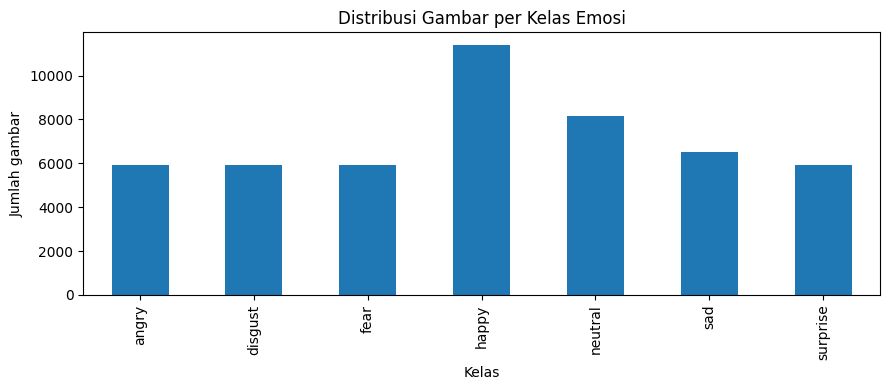

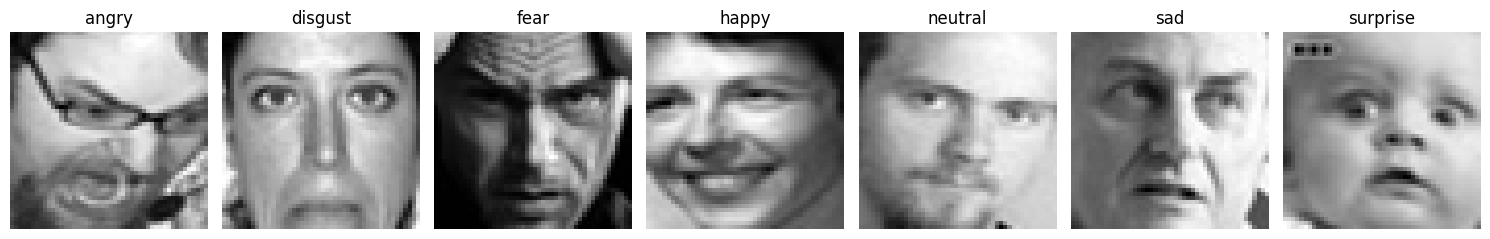

,width,height,mode,format
count,1000.0,1000.0,1000,1000
unique,NaN,NaN,1,1
top,NaN,NaN,RGB,JPEG
freq,NaN,NaN,1000,1000
mean,96.0,96.0,NaN,NaN
std,0.0,0.0,NaN,NaN
min,96.0,96.0,NaN,NaN
25%,96.0,96.0,NaN,NaN
50%,96.0,96.0,NaN,NaN
75%,96.0,96.0,NaN,NaN


mode
RGB    1000
Name: count, dtype: int64

,width,height,mode,format
count,1000.0,1000.0,1000,1000
unique,NaN,NaN,1,1
top,NaN,NaN,RGB,JPEG
freq,NaN,NaN,1000,1000
mean,96.0,96.0,NaN,NaN
std,0.0,0.0,NaN,NaN
min,96.0,96.0,NaN,NaN
25%,96.0,96.0,NaN,NaN
50%,96.0,96.0,NaN,NaN
75%,96.0,96.0,NaN,NaN


mode
RGB    1000
Name: count, dtype: int64

In [15]:
counts = df.label.value_counts().reindex(CLASS_NAMES, fill_value=0)
display(counts.to_frame("jumlah_gambar"))
plt.figure(figsize=(9,4))
counts.plot(kind="bar")
plt.title("Distribusi Gambar per Kelas Emosi")
plt.xlabel("Kelas"); plt.ylabel("Jumlah gambar"); plt.tight_layout()
plt.show()

def load_image(path):
    with Image.open(path) as im:
        return np.asarray(im.convert("L").resize((IMG_SIZE, IMG_SIZE)), dtype=np.float32)[...,None] / 255.0

fig, axes = plt.subplots(1, len(CLASS_NAMES), figsize=(15,3))
for ax, cls in zip(axes, CLASS_NAMES):
    subset = df[df.label == cls]
    ax.axis("off"); ax.set_title(cls)
    if len(subset):
        ax.imshow(load_image(subset.iloc[0].filepath).squeeze(), cmap="gray")
plt.tight_layout(); plt.show()

# Analisis ukuran dan format gambar menggunakan sampel
sample_df = df.sample(
    n=min(1000, len(df)),
    random_state=42
)

image_info = []

for path in sample_df.filepath:
    try:
        with Image.open(path) as im:
            image_info.append({
                "width": im.width,
                "height": im.height,
                "mode": im.mode,
                "format": im.format
            })
    except Exception:
        continue

image_info_df = pd.DataFrame(image_info)

display(image_info_df.describe(include="all"))
display(image_info_df["mode"].value_counts())
display(image_info_df.describe(include="all"))
display(image_info_df["mode"].value_counts(dropna=False))

## 4. Preprocessing dan pembagian data

In [16]:
def prepare_arrays(frame):
    X = np.stack([load_image(p) for p in frame.filepath])
    y = np.array([CLASS_NAMES.index(label) for label in frame.label], dtype=np.int32)
    return X, y

train_df = df[df.split.isin(["train","training"])]
test_df = df[df.split.isin(["test","testing"])]
val_df = df[df.split.isin(["val","valid","validation"])]

if len(train_df):
    if len(val_df):
        X_train, y_train = prepare_arrays(train_df)
        X_val, y_val = prepare_arrays(val_df)
    else:
        Xa, ya = prepare_arrays(train_df)
        X_train, X_val, y_train, y_val = train_test_split(Xa, ya, test_size=0.20,
                                                          random_state=SEED, stratify=ya)
    if len(test_df):
        X_test, y_test = prepare_arrays(test_df)
    else:
        X_test, y_test = X_val, y_val
else:
    Xa, ya = prepare_arrays(df)
    X_train, X_test, y_train, y_test = train_test_split(Xa, ya, test_size=TEST_SIZE,
                                                        random_state=SEED, stratify=ya)
    X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.20,
                                                      random_state=SEED, stratify=y_train)

print("Train:",len(X_train),"Validation:",len(X_val),"Test:",len(X_test))
print("Bentuk input:", X_train.shape, "| rentang piksel:", X_train.min(), "-", X_train.max())

Train: 31858 Validation: 7965 Test: 9956
Bentuk input: (31858, 48, 48, 1) | rentang piksel: 0.0 - 1.0


## 5. Membangun arsitektur CNN

In [17]:
def build_cnn(num_classes):
    inputs = tf.keras.Input(shape=(IMG_SIZE, IMG_SIZE, 1))
    x = tf.keras.layers.RandomFlip("horizontal")(inputs)
    x = tf.keras.layers.RandomRotation(0.08)(x)
    x = tf.keras.layers.RandomZoom(0.10)(x)
    for filters in [32,64,128]:
        x = tf.keras.layers.Conv2D(filters,3,padding="same",use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation("relu")(x)
        x = tf.keras.layers.Conv2D(filters,3,padding="same",use_bias=False)(x)
        x = tf.keras.layers.BatchNormalization()(x)
        x = tf.keras.layers.Activation("relu")(x)
        x = tf.keras.layers.MaxPooling2D()(x)
        x = tf.keras.layers.Dropout(0.25)(x)
    x = tf.keras.layers.GlobalAveragePooling2D()(x)
    x = tf.keras.layers.Dense(128,activation="relu")(x)
    x = tf.keras.layers.Dropout(0.40)(x)
    outputs = tf.keras.layers.Dense(num_classes,activation="softmax")(x)
    model = tf.keras.Model(inputs,outputs)
    model.compile(optimizer=tf.keras.optimizers.Adam(LEARNING_RATE),
                  loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    return model

model = build_cnn(len(CLASS_NAMES))
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 48, 48, 1)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 48, 48, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 48, 48, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 48, 48, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 24, 24, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 24, 24, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 24, 24, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 12, 12, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 305,191 (1.16 MB)

 Trainable params: 304,295 (1.16 MB)

 Non-trainable params: 896 (3.50 KB)

## 6. Training model CNN

In [18]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss",patience=7,restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=0.5,patience=3,min_lr=1e-6),
    tf.keras.callbacks.ModelCheckpoint(OUTPUT_DIR/"best_model.keras",monitor="val_loss",save_best_only=True)
]
history = model.fit(X_train,y_train,validation_data=(X_val,y_val),epochs=EPOCHS,
                    batch_size=BATCH_SIZE,callbacks=callbacks,verbose=1)
model = tf.keras.models.load_model(OUTPUT_DIR/"best_model.keras")
model.save(OUTPUT_DIR/"emotion_cnn.keras")
pd.DataFrame(history.history).to_csv(OUTPUT_DIR/"training_history.csv",index=False)

Epoch 1/30
996/996 ━━━━━━━━━━━━━━━━━━━━ 392s 380ms/step - accuracy: 0.2410 - loss: 1.8792 - val_accuracy: 0.2930 - val_loss: 1.7732 - learning_rate: 0.0010
Epoch 2/30
996/996 ━━━━━━━━━━━━━━━━━━━━ 476s 478ms/step - accuracy: 0.3416 - loss: 1.6920 - val_accuracy: 0.4187 - val_loss: 1.5461 - learning_rate: 0.0010
Epoch 3/30
996/996 ━━━━━━━━━━━━━━━━━━━━ 614s 617ms/step - accuracy: 0.4302 - loss: 1.5177 - val_accuracy: 0.3956 - val_loss: 1.5725 - learning_rate: 0.0010
Epoch 4/30
996/996 ━━━━━━━━━━━━━━━━━━━━ 498s 492ms/step - accuracy: 0.4650 - loss: 1.4320 - val_accuracy: 0.3800 - val_loss: 1.6367 - learning_rate: 0.0010
Epoch 5/30
996/996 ━━━━━━━━━━━━━━━━━━━━ 451s 453ms/step - accuracy: 0.4894 - loss: 1.3737 - val_accuracy: 0.4863 - val_loss: 1.3610 - learning_rate: 0.0010
Epoch 6/30
996/996 ━━━━━━━━━━━━━━━━━━━━ 434s 435ms/step - accuracy: 0.5002 - loss: 1.3323 - val_accuracy: 0.4097 - val_loss: 1.5511 - learning_rate: 0.0010
Epoch 7/30
996/996 ━━━━━━━━━━━━━━━━━━━━ 436s 438ms/step - accura

## 7. Visualisasi akurasi dan loss

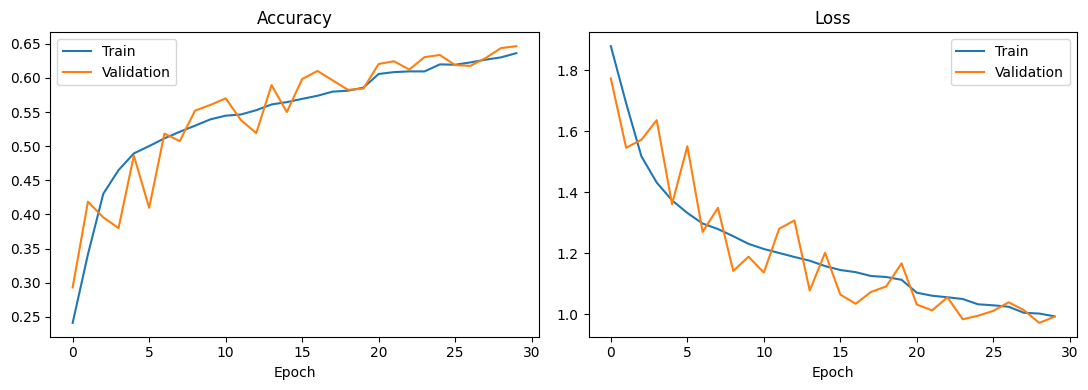

In [19]:
hist = pd.DataFrame(history.history)
fig, ax = plt.subplots(1,2,figsize=(11,4))
ax[0].plot(hist.accuracy,label="Train"); ax[0].plot(hist.val_accuracy,label="Validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(hist.loss,label="Train"); ax[1].plot(hist.val_loss,label="Validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"training_curves.png",dpi=150); plt.show()

## 8. Evaluasi model

In [20]:
probabilities = model.predict(X_test,verbose=0)
y_pred = np.argmax(probabilities,axis=1)
metrics = {
    "accuracy": float(accuracy_score(y_test,y_pred)),
    "precision_weighted": float(precision_score(y_test,y_pred,average="weighted",zero_division=0)),
    "recall_weighted": float(recall_score(y_test,y_pred,average="weighted",zero_division=0)),
    "f1_weighted": float(f1_score(y_test,y_pred,average="weighted",zero_division=0))
}
display(pd.DataFrame([metrics]).T.rename(columns={0:"nilai"}))
report = classification_report(y_test,y_pred,labels=list(range(len(CLASS_NAMES))),
                               target_names=CLASS_NAMES,output_dict=True,zero_division=0)
display(pd.DataFrame(report).transpose())
with open(OUTPUT_DIR/"metrics.json","w") as f: json.dump(metrics,f,indent=2)
pd.DataFrame(report).transpose().to_csv(OUTPUT_DIR/"classification_report.csv")

,nilai
accuracy,0.645641
precision_weighted,0.645212
recall_weighted,0.645641
f1_weighted,0.642971


,precision,recall,f1-score,support
angry,0.589367,0.440034,0.503868,1184.000000
disgust,0.704098,0.725507,0.714642,1184.000000
fear,0.434236,0.379223,0.404869,1184.000000
happy,0.852747,0.850877,0.851811,2280.000000
neutral,0.613734,0.612982,0.613358,1633.000000
sad,0.471875,0.577659,0.519436,1307.000000
surprise,0.688262,0.762669,0.723558,1184.000000
accuracy,0.645641,0.645641,0.645641,0.645641
macro avg,0.622046,0.621279,0.618792,9956.000000
weighted avg,0.645212,0.645641,0.642971,9956.000000


## 9. Confusion matrix dan contoh prediksi

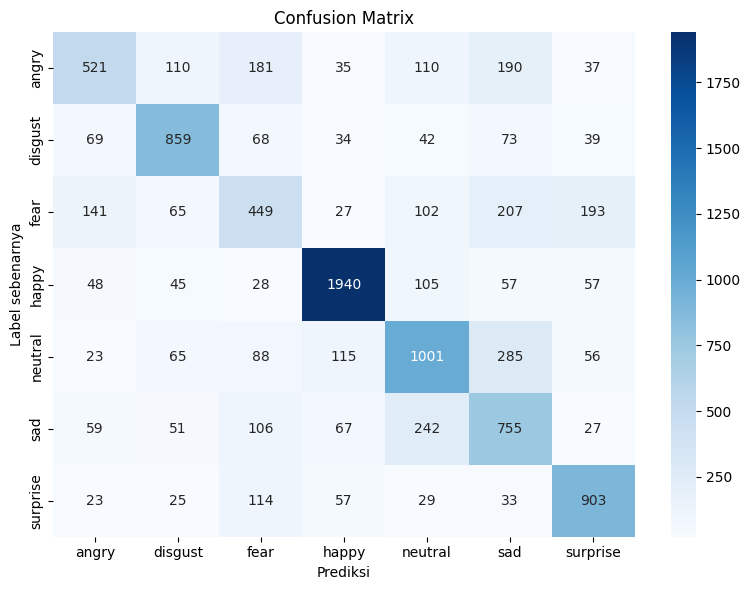

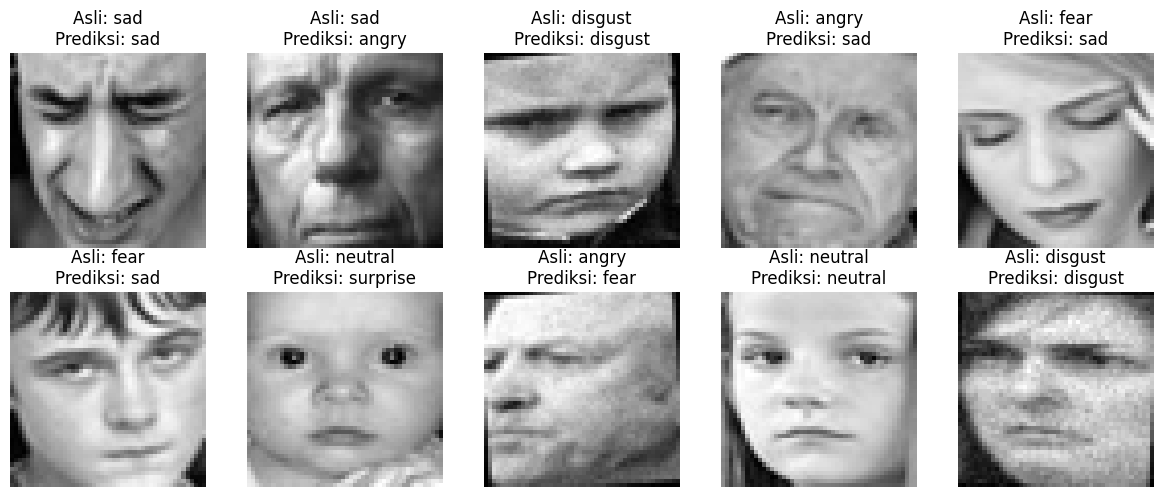

In [21]:
cm = confusion_matrix(y_test,y_pred,labels=list(range(len(CLASS_NAMES))))
plt.figure(figsize=(8,6))
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues",xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES)
plt.xlabel("Prediksi"); plt.ylabel("Label sebenarnya"); plt.title("Confusion Matrix")
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"confusion_matrix.png",dpi=150); plt.show()

fig, axes = plt.subplots(2,5,figsize=(12,5))
for i, ax in enumerate(axes.flat):
    if i >= len(X_test): break
    ax.imshow(X_test[i].squeeze(),cmap="gray")
    ax.set_title(f"Asli: {CLASS_NAMES[y_test[i]]}\nPrediksi: {CLASS_NAMES[y_pred[i]]}")
    ax.axis("off")
plt.tight_layout(); plt.show()

## 10. Visualisasi area penting dengan Grad-CAM

c:\Users\ASUS\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\models\functional.py:259: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer']
Received: inputs=Tensor(shape=(1, 48, 48, 1))
  warnings.warn(msg)


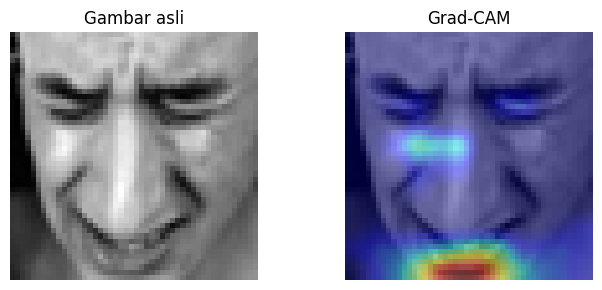

In [22]:
# Grad-CAM membantu melihat area citra yang berkontribusi pada prediksi model.
last_conv = next(layer for layer in reversed(model.layers) if isinstance(layer, tf.keras.layers.Conv2D))
grad_model = tf.keras.Model(model.inputs, [last_conv.output, model.output])
sample = X_test[:1]
with tf.GradientTape() as tape:
    conv_outputs, pred_outputs = grad_model(sample)
    class_index = tf.argmax(pred_outputs[0])
    class_score = pred_outputs[:, class_index]
grads = tape.gradient(class_score, conv_outputs)
weights = tf.reduce_mean(grads, axis=(0,1,2))
cam = tf.reduce_sum(conv_outputs[0] * weights, axis=-1)
cam = tf.maximum(cam, 0)
cam = cam / (tf.reduce_max(cam) + 1e-8)
cam = tf.image.resize(cam[...,None], (IMG_SIZE,IMG_SIZE)).numpy().squeeze()

fig, ax = plt.subplots(1,2,figsize=(7,3))
ax[0].imshow(sample[0].squeeze(),cmap="gray"); ax[0].set_title("Gambar asli"); ax[0].axis("off")
ax[1].imshow(sample[0].squeeze(),cmap="gray")
ax[1].imshow(cam,cmap="jet",alpha=0.45); ax[1].set_title("Grad-CAM"); ax[1].axis("off")
plt.tight_layout(); plt.savefig(OUTPUT_DIR/"gradcam.png",dpi=150); plt.show()

## 11. Simpan artefak untuk Streamlit


In [23]:
with open(OUTPUT_DIR/"class_names.json","w",encoding="utf-8") as f:
    json.dump(CLASS_NAMES,f,ensure_ascii=False,indent=2)
with open(OUTPUT_DIR/"config.json","w",encoding="utf-8") as f:
    json.dump({"img_size":IMG_SIZE,"color_mode":"grayscale","classes":CLASS_NAMES},f,indent=2)
print("Artefak tersimpan di:",OUTPUT_DIR.resolve())

Artefak tersimpan di: C:\Semester 7\Analilisis Big Data\Klasifikasi Citra Emosi Wajah Menggunakan CNN\outputs
